# Derivatives and quadrature

**Source:** CompSci §§4.2–4.3, 5.2 (prerequisite bridge) · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

Taylor expansions at $x\pm h$ give forward and centred derivatives of order one and two respectively. Adding the expansions gives the centred second derivative $(f(x+h)-2f(x)+f(x-h))/h^2$. Subtraction of nearby floating-point values eventually makes smaller $h$ worse. The trapezoid rule integrates a piecewise linear approximation and has second-order global error for smooth functions.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


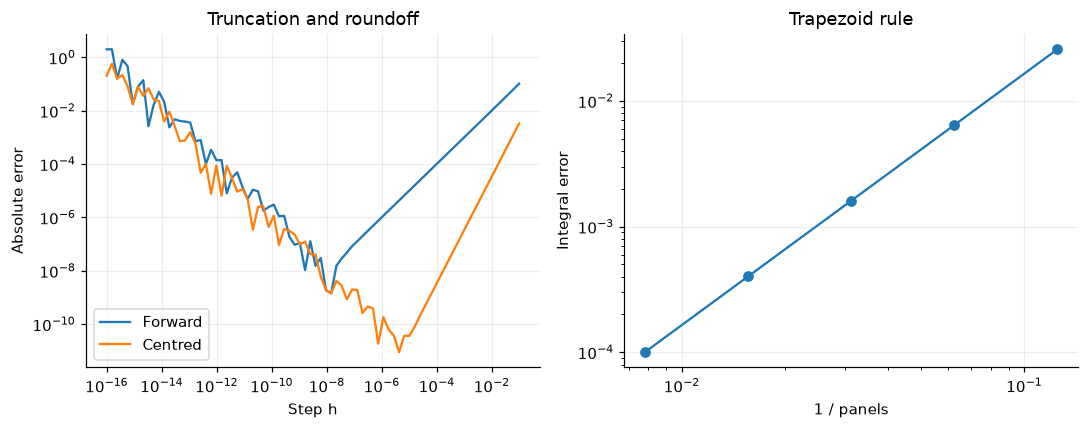

Trapezoid orders: [2.00278934 2.00069577 2.00017385 2.00004346]


In [2]:
x=.7
h=np.logspace(-1,-16,80)
fwd=abs((np.exp(x+h)-np.exp(x))/h-np.exp(x))
ctr=abs((np.exp(x+h)-np.exp(x-h))/(2*h)-np.exp(x))
n=np.array([8,16,32,64,128])
def error(n):
    x=np.linspace(0,np.pi,n+1)
    return abs(np.trapezoid(np.sin(x),x)-2)
e=np.array([error(k) for k in n])
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].loglog(h,fwd,label="Forward"); ax[0].loglog(h,ctr,label="Centred")
ax[0].set(xlabel="Step h",ylabel="Absolute error",title="Truncation and roundoff"); ax[0].legend()
ax[1].loglog(1/n,e,"o-"); ax[1].set(xlabel="1 / panels",ylabel="Integral error",title="Trapezoid rule")
show(fig,"01-derivatives")
assert np.allclose(np.log2(e[:-1]/e[1:]),2,atol=.02)
assert ctr[-1]>min(ctr)
print("Trapezoid orders:", np.log2(e[:-1]/e[1:]))

## Worked exercise

**Why does halving the step divide the centred truncation error by four?** Its leading term scales as $h^2$. This argument stops applying when roundoff dominates.